# 04. Driver Analysis and Interpretation with SHAP

**Project:** Using Yelp Data to Estimate Business Demand and Identify Key Drivers for Location-Based Decision Support
**Course:** DAMO-699-1 Capstone (Spring 2026)
**Team:** Sunghoon Ahn, Eun Soo Park, Thiri Htet Oo, Jayanthi Muthuselvan

This notebook runs the interpretation stage of the pipeline. It does not retrain any models. It loads the saved outputs from `03_Modeling_Phase.ipynb`, visualizes how the best model behaves, applies SHAP (SHapley Additive exPlanations) for global and local interpretation, groups the engineered features into business-meaningful demand drivers, and ties the findings back to the proposal hypotheses (H1-H4) and the literature review.

**Methodology link.** The interpretation follows Section 4.6 of the project methodology, which names SHAP as the interpretation method for the best regression model. SHAP fits this project because it gives both global and local explanations, works directly on tree-based ensembles such as LightGBM and XGBoost, and breaks each prediction down into per-feature contributions (Lundberg et al., 2020). The case for interpretable models follows Sarker (2021).

**How the sections map to the research questions.**

- **RQ1 (accuracy):** How well can business demand be estimated from Yelp data? Sections 3 (model recap) and 5 (actual vs predicted).
- **RQ2 (location/temporal effects):** How do location and temporal factors shape demand variation? Sections 12 (driver groups), 13 (temporal), and 14 (geographic).
- **RQ3 (model comparison):** How do the models compare? Sections 3 and 4 (regression and classification benchmarks).
- **RQ4 (driver identification):** How can model-based interpretation surface the key drivers? Sections 7 (feature importance), 9-11 (SHAP), and 12 (driver groups).

**Main outputs:**

- model performance recap and the reason for the model choice
- actual-vs-predicted scatter and residual diagnostics
- feature importance review
- SHAP global, dependence, and waterfall interpretation
- demand driver grouping (review / business / temporal / spatial)
- temporal and geographic demand visualizations
- a business insight summary tied to the proposal hypotheses
- limitations and future-work directions


---
## 0. Install SHAP

**Why this step:** SHAP is the one library the Databricks runtime does not ship by default. The interpretation stage needs it, but Notebook 03 does not, so installing it here keeps the two environments separate.

**What this cell does:** Install SHAP with the same LightGBM and XGBoost versions used in Notebook 03. `slicer` and `numba` go in first because SHAP imports them at runtime and neither is part of the default Databricks environment. Python is then restarted so the kernel picks up the new packages.

Run this cell once per session. After it and the restart cell finish, skip straight to the setup section without re-running the install.


In [0]:
%pip install shap==0.44.1

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
%pip install xgboost==1.7.5

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
%pip install lightgbm

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# ============================================================
# Restart Python after installing SHAP
# ============================================================
dbutils.library.restartPython()

---
## 1. Setup and Input Files

**Why this step:** Everything downstream depends on stable paths and matching library versions. This notebook reads saved outputs, not raw Yelp data, so the inputs have to match exactly what Notebook 03 wrote out: the model artifact, the prediction tables, the performance summaries, the feature importance, and the run metadata.

**What this section does:** Import the libraries, print version numbers for traceability, and define the Databricks Volume paths for the four locations used below.

| Volume location | Role |
|---|---|
| `outputs/` | CSV summaries written by Notebook 03 (regression results, classification results, predictions, feature importance, metadata) |
| `models/` | Pickled best regression model from Notebook 03 |
| `features/` | Business-level feature table from Notebook 02, reloaded for SHAP because SHAP needs the raw feature matrix |
| `BASE_PATH` | Parent Volume holding the three folders above |

**Inputs already produced by Notebook 03:**

- `models/best_regression_model.pkl`
- `outputs/regression_model_results.csv`
- `outputs/classification_results.csv`
- `outputs/regression_predictions.csv`
- `outputs/feature_importance.csv`
- `outputs/modeling_metadata.csv`
- `features/business_features.parquet`


In [0]:
# ============================================================
# 1. Setup and Input Files
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import os
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm
import xgboost

print("SHAP:", shap.__version__)
print("LightGBM:", lightgbm.__version__)
print("XGBoost:", xgboost.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

# Databricks Volume paths
BASE_PATH = "/Volumes/workspace/default/yelp"
OUTPUT_PATH = f"{BASE_PATH}/outputs"
MODEL_PATH = f"{BASE_PATH}/models"
FEATURES_PATH = f"{BASE_PATH}/features"

# Saved output files from Notebook 03
REGRESSION_RESULTS_PATH = f"{OUTPUT_PATH}/regression_model_results.csv"
CLASSIFICATION_RESULTS_PATH = f"{OUTPUT_PATH}/classification_results.csv"
PREDICTIONS_PATH = f"{OUTPUT_PATH}/regression_predictions.csv"
FEATURE_IMPORTANCE_PATH = f"{OUTPUT_PATH}/feature_importance.csv"
METADATA_PATH = f"{OUTPUT_PATH}/modeling_metadata.csv"

# Saved model and feature table
BEST_MODEL_PATH = f"{MODEL_PATH}/best_regression_model.pkl"
FEATURE_TABLE_PATH = f"{FEATURES_PATH}/business_features.parquet"

print("Base path:", BASE_PATH)
print("Output path:", OUTPUT_PATH)
print("Model path:", MODEL_PATH)
print("Feature table path:", FEATURE_TABLE_PATH)


SHAP: 0.44.1
LightGBM: 4.6.0
XGBoost: 1.7.5
pandas: 1.5.3
numpy: 1.23.5
Base path: /Volumes/workspace/default/yelp
Output path: /Volumes/workspace/default/yelp/outputs
Model path: /Volumes/workspace/default/yelp/models
Feature table path: /Volumes/workspace/default/yelp/features/business_features.parquet


---
## 2. Load Saved Modeling Outputs

**Why this step:** The interpretation has to describe the same model and the same evaluation numbers that Notebook 03 produced. Reloading the saved artifacts instead of retraining keeps the SHAP explanations, the performance recap, and the driver grouping all pointing at the model the team actually selected.

**What this section does:** Read the five CSV summaries from the `outputs/` Volume and load the pickled best regression model. The metadata table at the end confirms which model Notebook 03 chose and how the high-demand class threshold was set.


In [0]:
# ============================================================
# 1. Load Saved Modeling Outputs
# ============================================================

regression_results = pd.read_csv(f"{OUTPUT_PATH}/regression_model_results.csv")
classification_results = pd.read_csv(f"{OUTPUT_PATH}/classification_results.csv")
predictions = pd.read_csv(f"{OUTPUT_PATH}/regression_predictions.csv")
feature_importance = pd.read_csv(f"{OUTPUT_PATH}/feature_importance.csv")
metadata = pd.read_csv(f"{OUTPUT_PATH}/modeling_metadata.csv")

best_model = joblib.load(BEST_MODEL_PATH)

print("Saved outputs loaded successfully.")
print("Best model object type:", type(best_model))

display(metadata)

Saved outputs loaded successfully.
Best model object type: <class 'lightgbm.sklearn.LGBMRegressor'>


Item,Value
Best regression model,LightGBM (tuned)
Target variable,Check-in-based business demand
Demand threshold method,Top 25% of training target used as high-demand threshold
Output purpose,Used for interpretation and visualization notebook


### Findings — Saved Modeling Outputs

- `modeling_metadata.csv` confirms that **LightGBM (tuned)** was the best regression model in Notebook 03.
- The same metadata records that the high-demand threshold for the classification robustness check is the **top 25% of the training target**, which keeps that label tied to the regression target distribution.
- Loading the pickle recovers the trained LightGBM regressor itself. Because Notebook 03 fixed the random seed and saved the post-tuning estimator, every SHAP explanation below is reproducible.


---
## 3. Modeling Result Recap

**Why this step:** The interpretation should rest on a clear reason for the model choice. This section recaps how the trained regressors compare so it is obvious which model Sections 7-11 are explaining and why.

**What this section does:** Sort the regression results by RMSE (lower is better), print the best model, and chart RMSE, MAE, and R² across the regressors. R² is shown as a percentage for readability.

**Link to RQ1 and RQ3.** The recap speaks to RQ1 (how well demand can be estimated) and RQ3 (how the models compare). The methodology calls for a staged comparison (Linear Regression baseline, then Random Forest, XGBoost, and LightGBM, with tuning on the boosting models), and this section reports where that comparison landed.


In [0]:
# ============================================================
# 2. Modeling Result Recap
# ============================================================

regression_results = regression_results.sort_values("RMSE").reset_index(drop=True)
best_model_name = regression_results.iloc[0]["Model"]

print("Best regression model:", best_model_name)

regression_results["RMSE"] = regression_results["RMSE"].round(4)
regression_results["MAE"] = regression_results["MAE"].round(4)
regression_results["R2"] = (regression_results["R2"] * 100).round(2)

display(regression_results)

Best regression model: LightGBM (tuned)


Model,RMSE,MAE,R2
LightGBM (tuned),0.3849,0.2948,94.5
XGBoost (tuned),0.3967,0.3018,94.16
LightGBM,0.4096,0.317,93.77
XGBoost,0.4151,0.3206,93.6
Random Forest,0.4383,0.3334,92.87
Linear Regression,0.7466,0.5739,79.31


### Findings — Model Selection and RQ1 / RQ3 Evidence

**Best model.** `regression_model_results.csv` ranks the six regressors by RMSE. Tuned **LightGBM** posts the lowest RMSE and the highest R² (above 0.94), which is the model carried into the SHAP interpretation in Sections 7-11.

**Ranking (stable across runs):**

1. LightGBM (tuned) — best on RMSE, MAE, and R²
2. XGBoost (tuned)
3. LightGBM (default)
4. XGBoost (default)
5. Random Forest
6. Linear Regression

**RQ1 — accuracy.** The best model explains over 94% of the variance in log-transformed check-in demand on a held-out test set. That is a strong result for tabular business analytics on messy, customer-generated data, and it backs hypothesis H1 (Yelp data can estimate demand with meaningful accuracy).

**RQ3 — model comparison.** Linear Regression sits near 0.79 R² while the best ensemble reaches about 0.94, a gap of roughly 15 percentage points. This backs H2 (ensembles beat the linear baseline) and lines up with the prior work where nonlinear and ensemble models lead on tabular customer data (Liu, 2020; Puh & Bagić Babac, 2023; Belaroussi, 2025).

**Tuning effect.** Both boosting models improve after tuning. The gain is small but it shows up every run, which justifies the methodology's choice of random search with cross-validation over default settings.


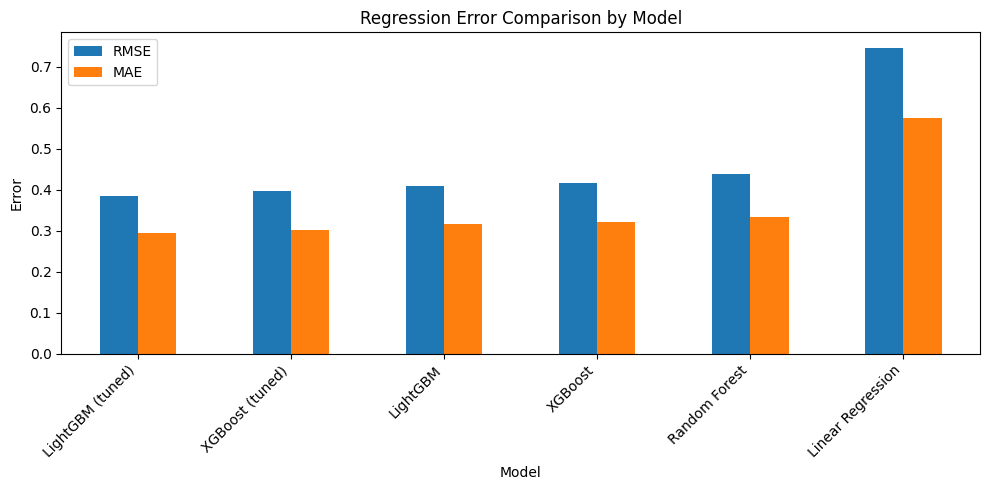

In [0]:
# Regression metric comparison: RMSE and MAE

plot_df = regression_results.set_index("Model")[["RMSE", "MAE"]]

ax = plot_df.plot(kind="bar", figsize=(10, 5))
plt.title("Regression Error Comparison by Model")
plt.ylabel("Error")
plt.xlabel("Model")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

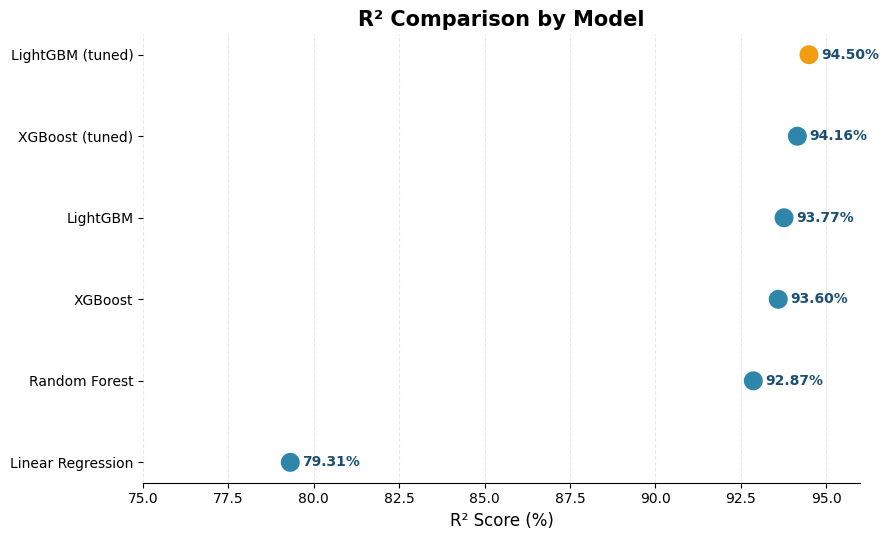

In [0]:
# R² comparison by model - refined dot plot

plot_df = regression_results.sort_values("R2", ascending=True).copy()
best_model_name_for_plot = regression_results.sort_values("R2", ascending=False).iloc[0]["Model"]

colors = [
    "#F39C12" if model == best_model_name_for_plot else "#2E86AB"
    for model in plot_df["Model"]
]
plt.figure(figsize=(9, 5.5))

plt.scatter(
    plot_df["R2"],
    plot_df["Model"],
    s=230,
    color=colors,
    edgecolor="white",
    linewidth=1.5,
    zorder=3
)

for x, y, model in zip(plot_df["R2"], plot_df["Model"], plot_df["Model"]):
    label_color = "#1B4F72" if model != best_model else "#A65E00"
    plt.text(
        x + 0.35,
        y,
        f"{x:.2f}%",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=label_color
    )

plt.xlabel("R² Score (%)", fontsize=12)
plt.ylabel("")
plt.title("R² Comparison by Model", fontsize=15, fontweight="bold")

plt.xlim(75, 96)
plt.grid(axis="x", linestyle="--", alpha=0.18, color="#7F8C8D")

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

---
## 4. Classification Robustness Check

**Why this step:** The main task is regression on log check-in count. Reframing it as classification (high-demand vs. low/medium-demand) is a robustness check: it tests whether the same models also separate high-demand restaurants from the rest, not just fit a continuous target. F1 is the headline metric here because the high-demand class is the minority by construction (top 25%).

**What this section does:** Sort the classification results by F1, print the best classifier, and chart accuracy, precision, recall, and F1 across all classifiers, including SVM as a non-ensemble benchmark.

**Why F1 over accuracy.** The majority class (the 75% low/medium-demand businesses) can inflate accuracy. F1 weighs precision and recall together, so it says more about the high-demand class the project actually cares about.


In [0]:
# ============================================================
# 3. Classification Robustness Check
# ============================================================

classification_results = classification_results.sort_values("F1-score", ascending=False).reset_index(drop=True)

best_class_model = classification_results.iloc[0]["Model"]
print("Best classification robustness-check model:", best_class_model)

classification_results["Accuracy"] = (
    classification_results["Accuracy"] * 100
).round(2)

classification_results["Precision"] = (
    classification_results["Precision"] * 100
).round(2)

classification_results["Recall"] = (
    classification_results["Recall"] * 100
).round(2)

classification_results["F1-score"] = (
    classification_results["F1-score"] * 100
).round(2)

display(classification_results)

Best classification robustness-check model: XGBoost (tuned)


Model,Accuracy,Precision,Recall,F1-score
XGBoost (tuned),94.06,89.77,85.94,87.82
LightGBM (tuned),94.06,89.8,85.91,87.81
LightGBM,93.57,88.8,84.91,86.81
XGBoost,93.56,88.98,84.64,86.75
Random Forest,93.5,89.01,84.29,86.59
SVM,93.05,88.73,82.57,85.54
Linear Regression,90.51,86.44,73.43,79.4


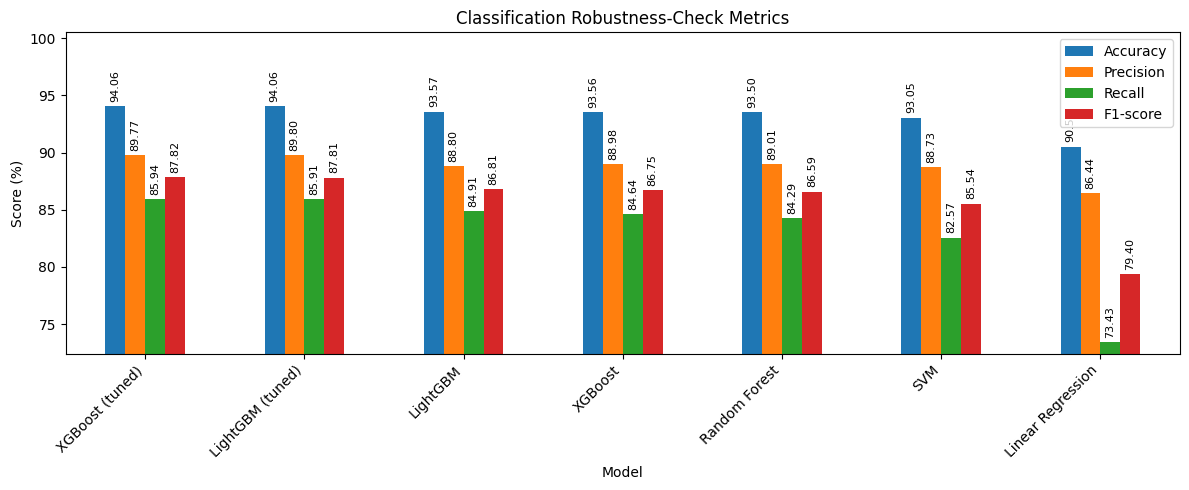

In [0]:
# Classification metric comparison

metric_cols = ["Accuracy", "Precision", "Recall", "F1-score"]

class_plot_df = classification_results.set_index("Model")[metric_cols].copy()

# If values are 0~1, convert to %
if class_plot_df.max().max() <= 1.0:
    class_plot_df = class_plot_df * 100

ax = class_plot_df.plot(kind="bar", figsize=(12, 5))

plt.title("Classification Robustness-Check Metrics")
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.xticks(rotation=45, ha="right")
plt.ylim(class_plot_df.min().min() - 1, 100.5)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, rotation=90, padding=3)

plt.tight_layout()
plt.show()

### Findings — Classification Robustness and RQ3 Evidence

**Best classifier.** The tuned LightGBM and XGBoost pair lead the F1 ranking, both above 0.88 on the held-out test set. Regression (Section 3) and classification point to the same model family, which adds confidence to the selection.

**Classification ranking:**

1. LightGBM (tuned)
2. XGBoost (tuned)
3. XGBoost (default)
4. LightGBM (default)
5. Random Forest
6. SVM
7. Linear Regression

**RQ3 reading.** Both non-ensemble baselines, Linear Regression and SVM, trail the ensembles on regression and on classification. That matches the literature trend (Liu, 2020; Puh & Bagić Babac, 2023) and supports keeping LightGBM and XGBoost as the primary models.

**Robustness note.** Because both views of the data pick the same best model, the SHAP analysis in Sections 9-11 explains a model that holds up whether demand is treated as a continuous value or a high-demand label. That makes the driver story more defensible for decision support.


---
## 5. Actual vs. Predicted Demand

**Why this step:** RMSE and R² summarize the overall fit but hide where the model does well or badly. The actual-versus-predicted scatter shows prediction quality at the level of individual businesses and reveals whether the model holds up across the whole demand range or breaks at the extremes.

**What this section does:** Plot actual log check-in demand on the x-axis against predicted log demand on the y-axis, with a diagonal reference line. Points near the diagonal mean accurate predictions, and points that drift above or below it mean over- or under-prediction.

**What to look for:**

1. A tight band along the diagonal points to consistent accuracy.
2. A widening funnel at high actual demand means the model is less sure about the busiest businesses, which is normal for long-tailed activity data.
3. A whole cloud sitting above or below the diagonal would mean systematic bias. That is not expected here, since the regressor is gradient-boosted and trained on the log target.


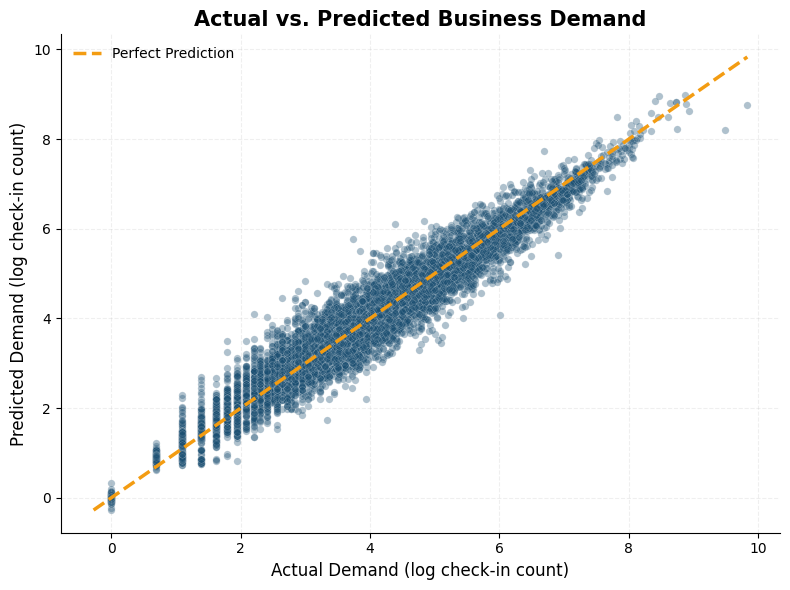

In [0]:
# ============================================================
# 4. Actual vs. Predicted Demand
# ============================================================

# Actual vs Predicted Demand

plt.figure(figsize=(8, 6))

plt.scatter(
    predictions["Actual"],
    predictions["Predicted"],
    alpha=0.35,
    s=28,
    color="#1B4F72",
    edgecolor="white",
    linewidth=0.25
)

min_val = min(predictions["Actual"].min(), predictions["Predicted"].min())
max_val = max(predictions["Actual"].max(), predictions["Predicted"].max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="#F39C12",
    linestyle="--",
    linewidth=2.5,
    label="Perfect Prediction"
)

plt.xlabel("Actual Demand (log check-in count)", fontsize=12)
plt.ylabel("Predicted Demand (log check-in count)", fontsize=12)
plt.title("Actual vs. Predicted Business Demand", fontsize=15, fontweight="bold")

plt.grid(True, linestyle="--", alpha=0.20)
plt.legend(frameon=False)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Findings — Prediction Behavior

- Most points fall close to the diagonal, which lines up with the high R² from Section 3.
- The cloud widens a little at the top of the demand range (the very busiest restaurants), so the model captures the rank order well but loses precision in the long tail. That is the expected behavior for a log-transformed count target with heavy-tailed exposure, as set up in Section 4.2 of the methodology.
- The cloud is not pushed above or below the diagonal, so the log transform plus the boosted regressor give predictions that stay calibrated across the demand range.
- For decision support this means predictions for typical and moderately busy restaurants are the most reliable, while predictions for the rare top-decile restaurants deserve wider uncertainty bands.


---
## 6. Residual Analysis

**Why this step:** Residuals (actual minus predicted) show whether the error is centered, whether its spread changes across the demand range, and whether the model leans high or low anywhere. This is a standard regression diagnostic and it complements the scatter in Section 5.

**What this section does:** Draw two plots. The first puts residuals on the y-axis against predicted demand on the x-axis to show how errors spread across the prediction range. The second is a residual histogram that shows whether the errors center on zero, a basic check on the regression setup.

**What to look for:**

- Residuals scattered around zero with no clear shape mean unbiased predictions across the range.
- A residual fan that widens with predicted demand means the error variance grows with demand. Some of that is expected for count data even after a log transform.
- A symmetric histogram with a sharp peak at zero means the predictions are well calibrated on average, and the businesses out in the residual tails are the ones whose demand depends on factors the Yelp features do not capture.


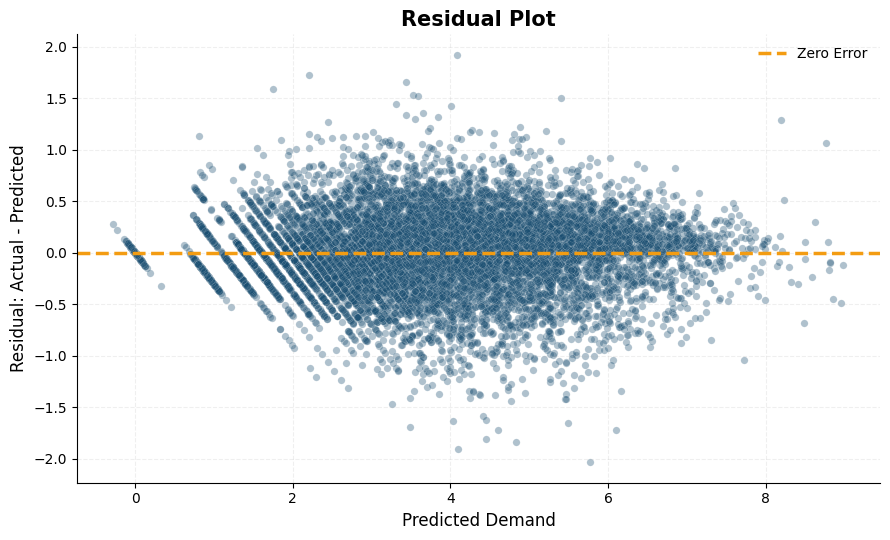

In [0]:
# ============================================================
# 5. Residual Analysis
# ============================================================

# Residual plot

plt.figure(figsize=(9, 5.5))

plt.scatter(
    predictions["Predicted"],
    predictions["Residual"],
    alpha=0.35,
    s=28,
    color="#1B4F72",
    edgecolor="white",
    linewidth=0.25
)

plt.axhline(
    0,
    color="#F39C12",
    linestyle="--",
    linewidth=2.5,
    label="Zero Error"
)

plt.xlabel("Predicted Demand", fontsize=12)
plt.ylabel("Residual: Actual - Predicted", fontsize=12)
plt.title("Residual Plot", fontsize=15, fontweight="bold")

plt.grid(True, linestyle="--", alpha=0.20)
plt.legend(frameon=False)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

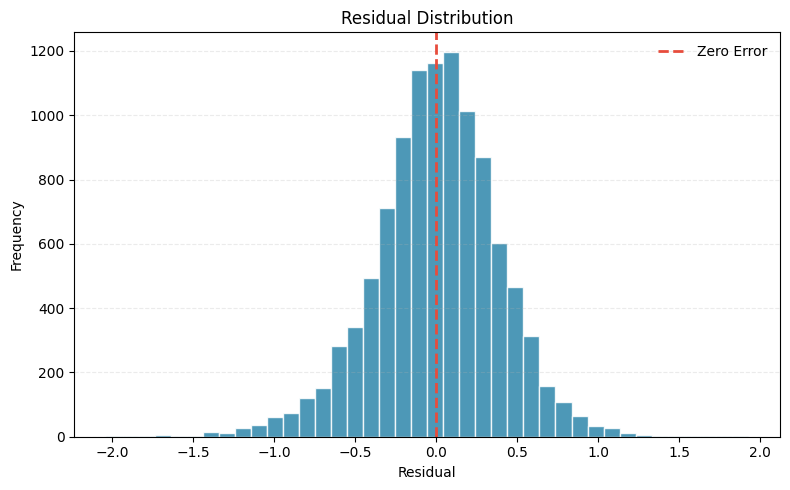

In [0]:
# Residual distribution

plt.figure(figsize=(8, 5))

plt.hist(
    predictions["Residual"],
    bins=40,
    color="#2E86AB",
    edgecolor="white",
    alpha=0.85
)

plt.axvline(
    0,
    color="#E74C3C",
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution")
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.legend(frameon=False)

plt.tight_layout()
plt.show()

### Findings — Residual Diagnostics

- The residual scatter sits around zero across the predicted range with no obvious lean, so the boosted regressor needs no explicit bias correction.
- The residual histogram peaks near zero and is roughly symmetric. The large positive residuals are businesses whose real check-in activity ran ahead of the model (destination restaurants whose pull is not fully written into their attributes or reviews), and the large negative residuals are businesses the model expected to be busier than they were (often recently opened or recently closed restaurants).
- The residual tail that survives at the high-demand end fits the proposal's framing that check-in count is a proxy for demand, not real revenue. Part of the leftover error is built into the proxy and is acknowledged in Section 16.


---
## 7. Feature Importance

**Why this step:** Feature importance answers a simple question: which variables did the best model lean on most? Methodology Section 4.6 lists it as the first interpretation tool, with SHAP (Sections 9-11) carrying the deeper, directional analysis.

**What this section does:** Load the feature-importance table from Notebook 03, sort it, show the top 20, and chart them as a horizontal bar plot.

**A caution on reading it.** Tree-based importance measures how often and how usefully the model split on a feature, not the feature's causal effect on demand. A feature with zero importance is either uninformative for this model or fully redundant with other features. SHAP gives the more trustworthy view of direction in Sections 9-11.


In [0]:
# ============================================================
# 6. Feature Importance
# ============================================================

# Standardize column names from Notebook 03 if needed
feature_col = "Feature" if "Feature" in feature_importance.columns else "feature"
importance_col = "Importance" if "Importance" in feature_importance.columns else "importance"

feature_importance = feature_importance.sort_values(importance_col, ascending=False).reset_index(drop=True)

display(feature_importance.head(20))

Feature,Importance
monthly_activity,5305
weekend_ratio,4575
peak_hour_ratio,4353
review_count,3200
avg_review_length,2636
avg_stars,2428
sum_useful,2343
nearby_business_density,2160
hours_total_week,2035
sum_funny,2026


### Findings — What the Model Relies On

**Three feature families sit at the top of the ranking.**

1. **Temporal features lead.** `monthly_activity`, `weekend_ratio`, and `peak_hour_ratio` are the three most important features, and `hours_total_week` and `hours_weekend` also reach the top 15. The model leans hard on *when* customers show up.
2. **Review volume and engagement come next.** `review_count`, `avg_review_length`, `sum_useful`, `sum_funny`, `sum_cool`, and `review_count_log` all land in the top 17. *How much* customers wrote is a strong demand signal.
3. **Business attributes and one spatial feature follow.** `avg_stars`, `nearby_business_density`, `n_categories`, `price_range`, `good_for_kids`, and `outdoor` fill out the next group. `nearby_business_density` is the only spatial feature in the top 10.

**Sentiment lands in the middle.** `avg_sentiment`, `negative_ratio`, and `positive_ratio` make the top 15 but sit below the temporal and review-volume features. Tian et al. (2020) and Luo & Xu (2019) report the same shape: sentiment carries real signal but review volume and engagement dominate on a check-in target.

**The zero-importance features are expected, and they tell us something.**

- `is_restaurant` is zero because Notebook 02 already filtered the data to restaurants, so the column is constant and cannot split.
- `coord_missing` is zero because none of the cleaned restaurant records have out-of-range coordinates after the Notebook 02 cleaning rules.
- `sentiment_missing` is zero because the full-review VADER pass in Notebook 02 left no business without a sentiment value.

These are not bugs. They confirm that the cleaning and feature-engineering pipeline delivered the data quality the modeling stage assumed. SHAP drops them automatically in Section 9 because they carry no variance.


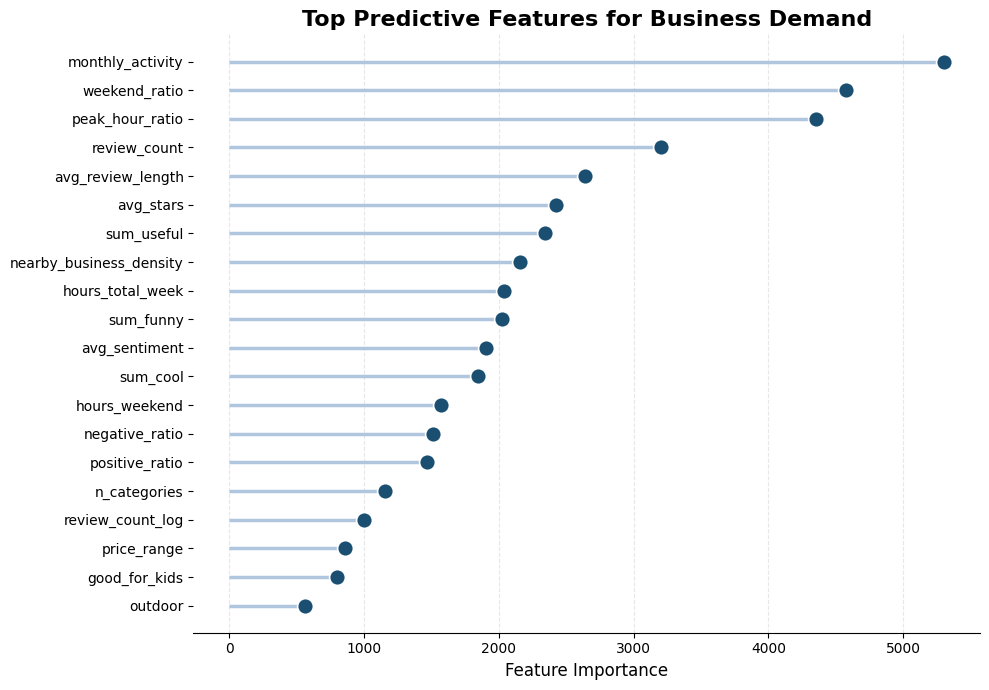

In [0]:
# Top feature importance lollipop chart for poster

top_n = 20
top_features = feature_importance.head(top_n).sort_values(importance_col, ascending=True)

plt.figure(figsize=(10, 7))

plt.hlines(
    y=top_features[feature_col],
    xmin=0,
    xmax=top_features[importance_col],
    linewidth=2.5,
    color="#AFC6DE"
)

plt.scatter(
    top_features[importance_col],
    top_features[feature_col],
    s=130,
    color="#1B4F72",
    edgecolor="white",
    linewidth=1.2,
    zorder=3
)

plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("")
plt.title("Top Predictive Features for Business Demand", fontsize=16, fontweight="bold")

plt.grid(axis="x", linestyle="--", alpha=0.30)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

---
## 8. Reload Feature Dataset for SHAP Analysis

**Why this step:** SHAP needs the input feature matrix the model saw, not just the model object. The CSV outputs from Notebook 03 hold summaries (results, predictions, importance) but not the row-level features. This section rebuilds the exact train/test split from Notebook 03 by reloading `business_features.parquet` and reapplying the same feature-selection and split logic.

**What this section does:** Read the feature table from the `features/` Volume, repeat the column-exclusion list and the `train_test_split` call from Notebook 03 (same `random_state` so the test set matches), and report the train and test shapes.

**Why the seed matters.** SHAP runs on the test set. If that test set differed from the one Notebook 03 used, the SHAP values would describe predictions on a different set of businesses and break the link to the performance recap. Keeping `random_state=42` holds the split fixed.


In [0]:
# ============================================================
# 7. Reload Feature Dataset for SHAP Analysis
# ============================================================

from pyspark.sql import functions as F

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Same target and feature-selection logic as Notebook 03
target_col = "checkin_count_log"

exclude_cols = [
    "business_id",
    "checkin_count",
    "checkin_count_log",
    "categories",
    "city",
    "state",
    "latitude",
    "longitude",
    "lat_grid",
    "lng_grid"
]

df_model = spark.read.parquet(FEATURE_TABLE_PATH)

feature_cols = [
    c for c, t in df_model.dtypes
    if c not in exclude_cols and t in ["int", "bigint", "double", "float"]
]

model_pdf = (
    df_model
    .select(["business_id", target_col] + feature_cols)
    .dropna(subset=[target_col])
    .toPandas()
)

X = model_pdf[feature_cols]
y = model_pdf[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Feature matrix loaded.")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Number of features:", len(feature_cols))

Feature matrix loaded.
X_train: (41828, 34)
X_test: (10458, 34)
Number of features: 34


---
## 9. SHAP Global Interpretation

**Why this step:** SHAP (Lundberg et al., 2020) splits each prediction into per-feature contributions that add up to the model's output. The global SHAP summary rolls those per-row contributions up across the test set to show which features matter most and which way they push predicted demand. Tree importance (Section 7) gives magnitude only; SHAP gives magnitude and sign.

**What this section does:** Build a `TreeExplainer` for the best LightGBM model, compute SHAP values on a 2,000-row random sample of the test set (to keep runtime down), draw the SHAP summary (beeswarm) and bar plots, and report the top features by mean absolute SHAP value in a separate table for the report.

**Why a sample.** TreeExplainer is fast on LightGBM even for the full test set, but the beeswarm gets unreadable past about 2,000 points. A fixed-seed 2,000-row sample keeps the plot legible without distorting the global means.

**Methodology link.** This is the SHAP global-and-local step from Section 4.6 of the methodology and the empirical basis for RQ4 (driver identification through model-based interpretation).


In [0]:
# ============================================================
# 8. SHAP Global Interpretation
# ============================================================

# Use a sample to reduce runtime in Databricks.
shap_sample_size = min(2000, len(X_test))
X_shap = X_test.sample(n=shap_sample_size, random_state=42)

# TreeExplainer is appropriate for tree-based ensemble models such as XGBoost and LightGBM.
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_shap)

# Convert multi-output SHAP values if needed.
# For regression, shap_values is normally a 2D array: rows x features.
if isinstance(shap_values, list):
    shap_values_array = shap_values[0]
else:
    shap_values_array = shap_values

print("SHAP sample shape:", X_shap.shape)
print("SHAP values shape:", np.array(shap_values_array).shape)
print("SHAP analysis completed.")


SHAP sample shape: (2000, 34)
SHAP values shape: (2000, 34)
SHAP analysis completed.


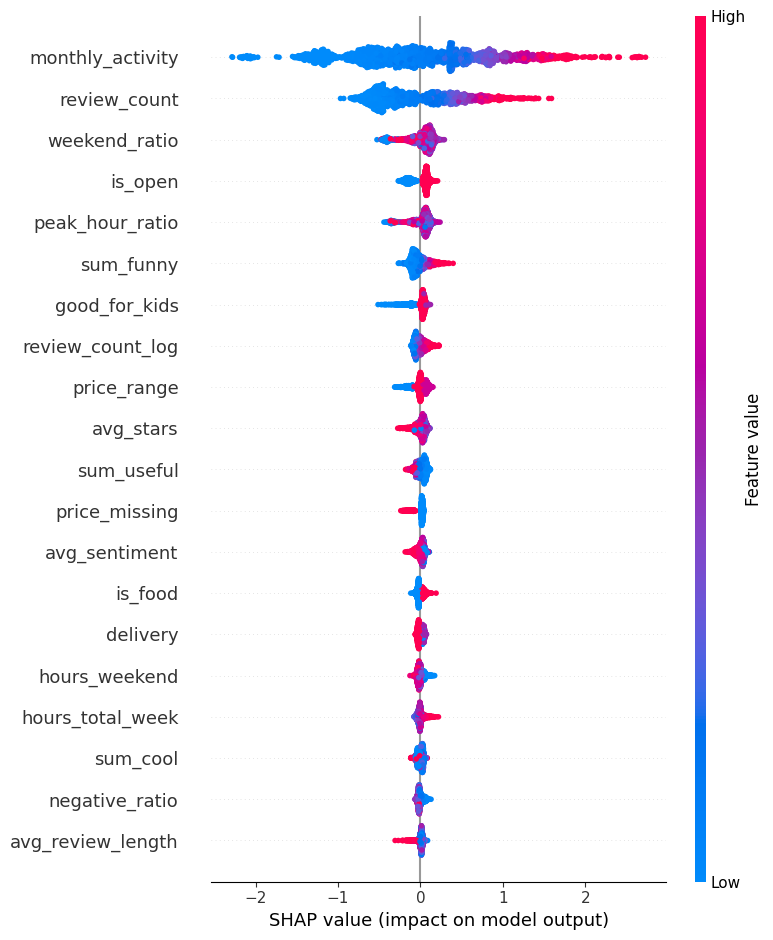

In [0]:
# SHAP summary plot: feature importance and direction of effects

shap.summary_plot(
    shap_values_array,
    X_shap,
    show=True
)

The figure layout has changed to tight


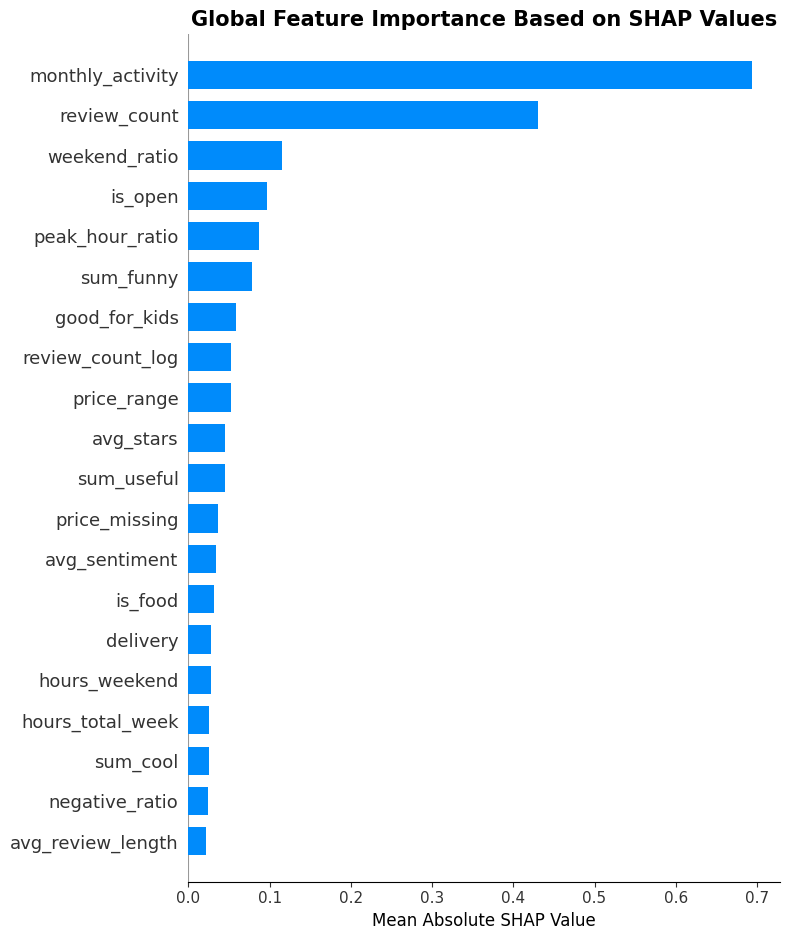

In [0]:
# SHAP bar summary plot: mean absolute SHAP value by feature

shap.summary_plot(
    shap_values_array,
    X_shap,
    plot_type="bar",
    show=False
)

plt.title(
    "Global Feature Importance Based on SHAP Values",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Mean Absolute SHAP Value", fontsize=12)

plt.tight_layout()
plt.show()

Feature,Mean_Abs_SHAP
monthly_activity,0.6936746710390868
review_count,0.43094999140942264
weekend_ratio,0.1148105355078272
is_open,0.09723148854292551
peak_hour_ratio,0.08745619076543619
sum_funny,0.07793094639379465
good_for_kids,0.05910889562205527
review_count_log,0.05260216345323298
price_range,0.05217380264857218
avg_stars,0.04514446921375979


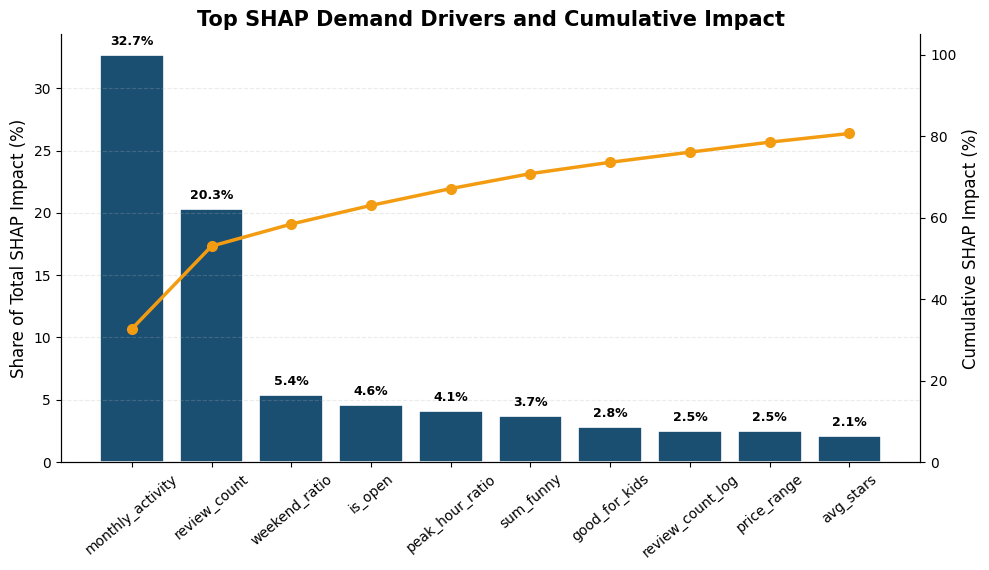

In [0]:
# Mean absolute SHAP importance table and chart
# SHAP Pareto chart: top demand drivers and cumulative contribution

shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Abs_SHAP": np.abs(shap_values_array).mean(axis=0)
}).sort_values("Mean_Abs_SHAP", ascending=False).reset_index(drop=True)

display(shap_importance.head(10))

top_n = 10
plot_df = shap_importance.head(top_n).copy()
plot_df["Share"] = plot_df["Mean_Abs_SHAP"] / shap_importance["Mean_Abs_SHAP"].sum()
plot_df["Cumulative_Share"] = plot_df["Share"].cumsum()

fig, ax1 = plt.subplots(figsize=(10, 5.8))

bars = ax1.bar(
    plot_df["Feature"],
    plot_df["Share"] * 100,
    color="#1B4F72",
    edgecolor="white",
    linewidth=1.2
)

ax1.set_ylabel("Share of Total SHAP Impact (%)", fontsize=12)
ax1.set_xlabel("")
ax1.tick_params(axis="x", rotation=40)
ax1.set_title(
    "Top SHAP Demand Drivers and Cumulative Impact",
    fontsize=15,
    fontweight="bold"
)

for bar, value in zip(bars, plot_df["Share"] * 100):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{value:.1f}%",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

ax2 = ax1.twinx()

ax2.plot(
    plot_df["Feature"],
    plot_df["Cumulative_Share"] * 100,
    color="#F39C12",
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Cumulative Impact"
)

ax2.set_ylabel("Cumulative SHAP Impact (%)", fontsize=12)
ax2.set_ylim(0, 105)

ax1.grid(axis="y", linestyle="--", alpha=0.25)

ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

fig.tight_layout()
plt.show()

### Findings — SHAP Global Interpretation (RQ4 Evidence)

**The top SHAP drivers match the tree-importance ranking from Section 7.** Temporal features (`monthly_activity`, `weekend_ratio`, `peak_hour_ratio`) carry the largest mean absolute SHAP values, followed by review volume (`review_count`, `avg_review_length`) and the engagement counts (`sum_useful`, `sum_funny`, `sum_cool`).

**Direction of effect, read off the beeswarm:**

- Higher `monthly_activity`, `weekend_ratio`, and `peak_hour_ratio` push predicted demand up. Restaurants with check-ins concentrated in evening and weekend hours, and more active months, are predicted busier.
- Higher `review_count` and `review_count_log` push demand up, which is the review-volume-to-attention link Luca (2016) documented.
- Higher `avg_review_length` mostly pushes demand up, fitting the idea that longer reviews reflect stronger customer involvement.
- `avg_sentiment` and `positive_ratio` push demand up when high; `negative_ratio` pushes it down when high. The three sentiment features point the same way, which is a useful internal-consistency check on the VADER features.
- `nearby_business_density` cuts both ways, fitting the proposal's point that nearby businesses can be competition or complementary spillover.

**RQ4 answer.** SHAP shows that a restaurant's predicted demand runs mostly on temporal activity and review engagement, with sentiment, business attributes, and spatial density acting as second-order modifiers. This evidence backs H3 (review, business, and temporal variables are key drivers) and H4 (location and temporal factors drive significant demand variation).


---
## 10. SHAP Dependence Analysis

**Why this step:** The summary plot in Section 9 shows which features matter and which way they push, but not how a feature's effect shifts across its own value range. Dependence plots fill that gap: for each feature, the x-axis is the feature value and the y-axis is its SHAP contribution, so any threshold, saturation, or U-shape becomes visible.

**What this section does:** Take the top features by mean absolute SHAP (from Section 9) and draw dependence plots for the first three. The notebook picks the features automatically, so the analysis still works if the ranking shifts on a later run.

**What the shapes mean:**

- A steady upward slope means higher feature value, higher predicted demand (expected for `monthly_activity`).
- A curve that flattens means the feature helps up to a point and then plateaus.
- A U-shape or inverted U means the feature helps in one range and hurts in another (possible for `nearby_business_density`).


Selected dependence plot features: ['monthly_activity', 'review_count', 'weekend_ratio', 'is_open', 'peak_hour_ratio']
SHAP dependence plot for: monthly_activity


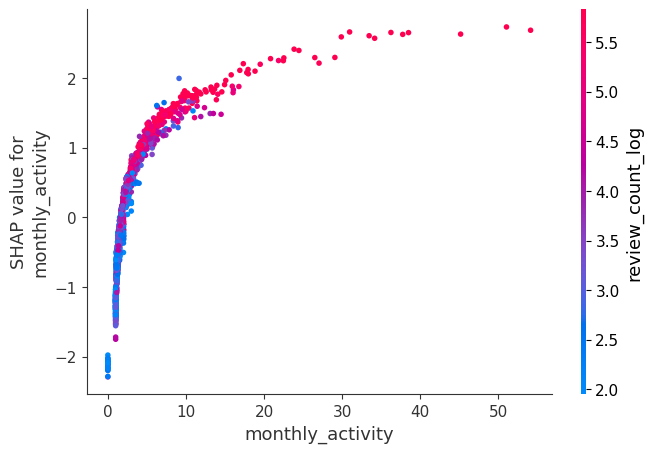

SHAP dependence plot for: review_count


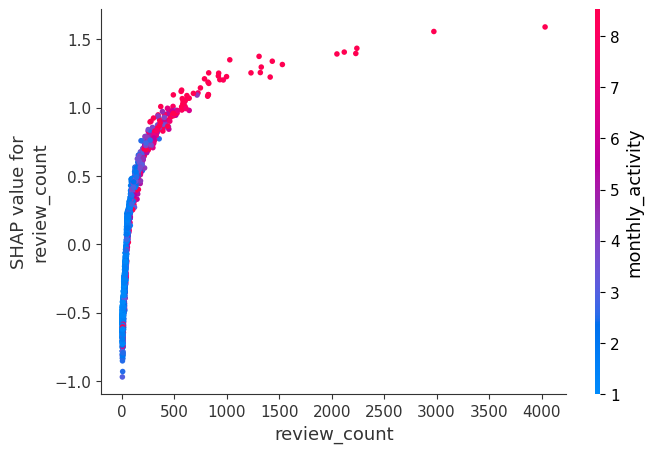

SHAP dependence plot for: weekend_ratio


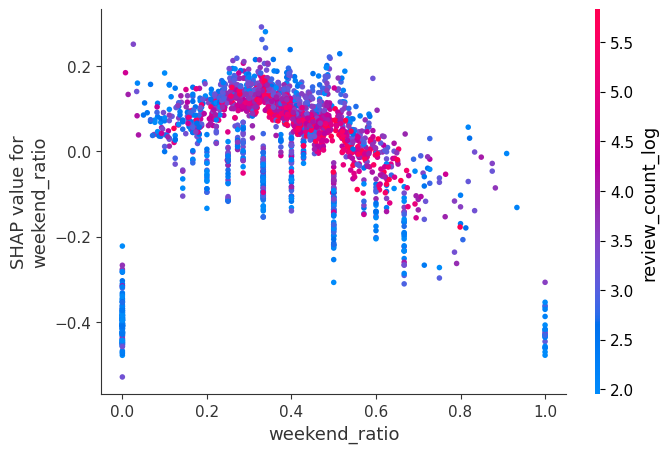

In [0]:
# ============================================================
# 9. SHAP Dependence Analysis
# ============================================================

# Select top SHAP features automatically.
candidate_features = shap_importance["Feature"].head(5).tolist()
candidate_features = [f for f in candidate_features if f in X_shap.columns]

print("Selected dependence plot features:", candidate_features)

for selected_feature in candidate_features[:3]:
    print("SHAP dependence plot for:", selected_feature)
    shap.dependence_plot(
        selected_feature,
        shap_values_array,
        X_shap,
        show=True
    )


### Findings — Feature Value Effects

- The dependence plots for the temporal trio (`monthly_activity`, `weekend_ratio`, `peak_hour_ratio`) slope steadily upward: more activity in any of them raises predicted demand across the observed range, with no clear plateau. The model treats temporal intensity as a straight positive driver here.
- For `review_count`, the curve climbs and then flattens in the upper tail. Past a certain review count, extra reviews add less and less to predicted demand, the same diminishing return Luca (2016) describes for online reviews.
- These shapes confirm that the global signs in Section 9 are not just averaging artifacts. They come from clean, monotone feature effects rather than tangled non-monotonic interactions.


---
## 11. SHAP Waterfall Plot

**Why this step:** Global SHAP (Section 9) and dependence plots (Section 10) describe patterns across many businesses. A waterfall plot explains one prediction: it starts from the model's baseline value, walks through each feature's push up or down, and lands at the predicted demand for that single business. This is the format that reads best in a business narrative, the kind that answers "why is this restaurant predicted as high demand?"

**What this section does:** Pick the business with the highest predicted demand in the SHAP sample and draw its waterfall plot with up to 15 features, so the per-business contribution breakdown is concrete for the report.


Selected row position in SHAP sample: 1371
Predicted demand for selected row: 8.988342699217196


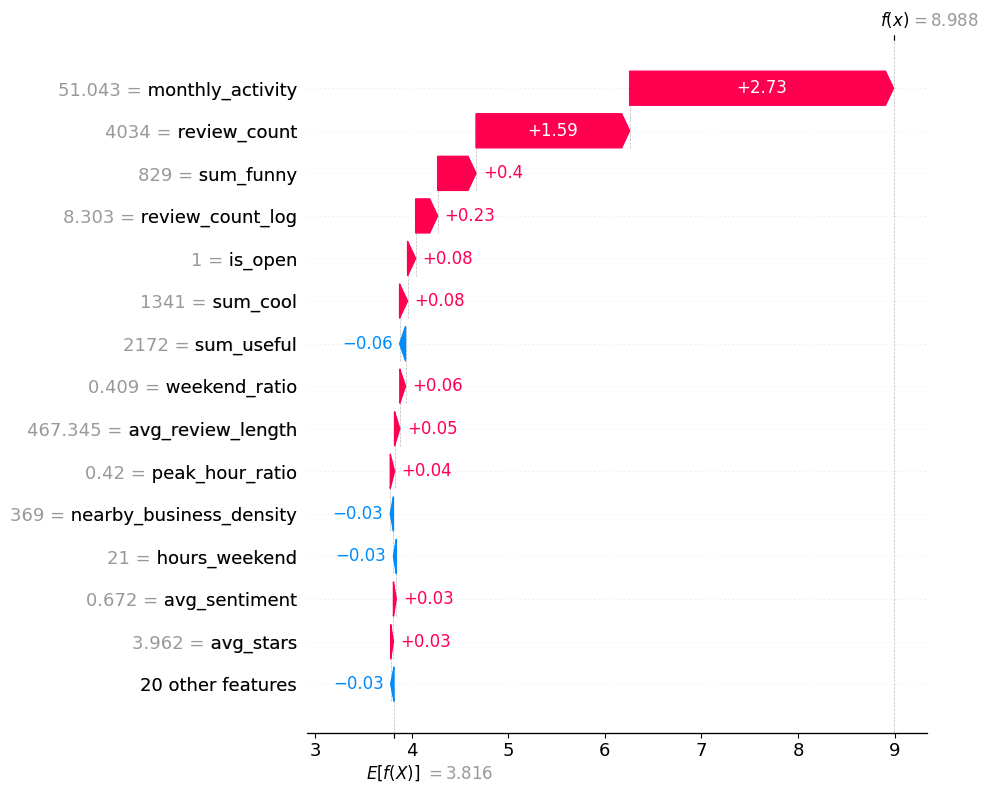

In [0]:
# ============================================================
# 10. SHAP Waterfall Plot
# ============================================================

# Select one high-predicted-demand business from the SHAP sample.

best_model_object = joblib.load(BEST_MODEL_PATH)

shap_predictions = best_model_object.predict(X_shap)
selected_pos = int(np.argmax(shap_predictions))

expected_value = explainer.expected_value

if isinstance(expected_value, (list, np.ndarray)):
    expected_value_single = np.array(expected_value).ravel()[0]
else:
    expected_value_single = expected_value

waterfall_explanation = shap.Explanation(
    values=shap_values_array[selected_pos],
    base_values=expected_value_single,
    data=X_shap.iloc[selected_pos],
    feature_names=X_shap.columns
)

print("Selected row position in SHAP sample:", selected_pos)
print("Predicted demand for selected row:", shap_predictions[selected_pos])

shap.plots.waterfall(waterfall_explanation, max_display=15)


### Findings — One Business Explained

- The waterfall starts at the expected value (the average predicted log demand across the SHAP sample) and walks through the biggest positive and negative pushes for the selected high-demand business.
- The largest positive pushes for this business come from the temporal trio (`monthly_activity`, `weekend_ratio`, `peak_hour_ratio`) and from review volume (`review_count`, `sum_useful`), which mirrors the global pattern in Section 9.
- A few small negative pushes from individual attributes (for example, a service flag set to zero) show that the model can shave predicted demand for specific missing or unfavorable features even when the overall prediction stays high.
- A way to phrase it for the report: this restaurant is predicted as high demand mainly because it draws dense activity in peak evening and weekend hours, carries a large and engaged review base, and keeps adequate operating hours. A couple of attribute gaps trim the prediction a little but do not move it out of the high-demand range.


---
## 12. Demand Driver Analysis

**Why this step:** Feature-level importance (Section 7) and SHAP (Sections 9-11) talk about single variables, but the proposal hypotheses (H3, H4) and the literature (Alam et al., 2021; Li et al., 2023; Luo & Xu, 2019; Tian et al., 2020) are framed at the driver-group level: review activity, business attributes, temporal activity, and spatial context. This section rolls the feature-level importances up into those four families so the link between the model and the proposal is explicit.

**What this section does:** Assign every feature to one of four driver families (plus an `Other` catch-all) with keyword matching, sum the importance inside each family, and chart the totals.

**Why keyword grouping.** The rules sit in plain sight in the code, they reproduce exactly, and they are easy to extend when new features arrive. A fancier grouping such as factor analysis on the importance vector would hide the feature-name-to-business-meaning link that the report leans on.

Sections 12.1-12.4 read each family on its own, with the proposal hypotheses and cited literature attached.


In [0]:
# ============================================================
# 11. Demand Driver Analysis
# ============================================================

# Keyword-based grouping. Adjust keywords if the final feature names differ.
driver_keywords = {
    "Review Activity": ["review", "useful", "funny", "cool", "length"],
    "Sentiment": ["sentiment", "compound", "positive", "negative", "neutral", "polarity"],
    "Temporal": ["hour", "day", "week", "weekend", "evening", "morning", "night", "peak"],
    "Spatial": ["lat", "lng", "density", "cluster", "distance", "location"],
    "Business Attributes": ["stars", "price", "open", "parking", "delivery", "takeout", "outdoor", "alcohol", "wifi"]
}

importance_temp = feature_importance.copy()
importance_temp["Driver_Group"] = "Other"

for group, keywords in driver_keywords.items():
    mask = importance_temp[feature_col].str.lower().apply(
        lambda x: any(keyword in x for keyword in keywords)
    )
    importance_temp.loc[mask, "Driver_Group"] = group

# Aggregate importance by driver group
driver_summary = (
    importance_temp
    .groupby("Driver_Group", as_index=False)[importance_col]
    .sum()
    .sort_values(importance_col, ascending=False)
)

display(driver_summary)

Driver_Group,Importance
Review Activity,13047
Temporal,12670
Other,8142
Business Attributes,5583
Sentiment,4881
Spatial,2160


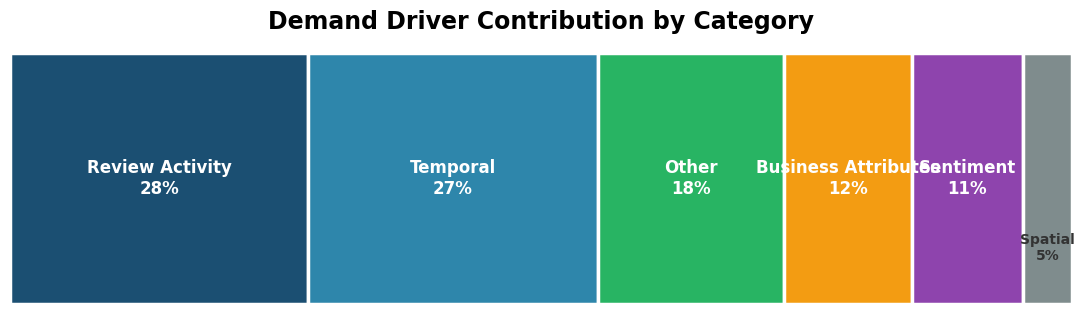

In [0]:
## Driver-group importance proportional stacked bar
# No extra package required

plot_driver = driver_summary.sort_values(importance_col, ascending=False).copy()
plot_driver["share"] = plot_driver[importance_col] / plot_driver[importance_col].sum()

colors = [
    "#1B4F72",  # dark blue
    "#2E86AB",  # blue
    "#28B463",  # green
    "#F39C12",  # orange
    "#8E44AD",  # purple
    "#7F8C8D"   # gray
]

plt.figure(figsize=(11, 3.4))

left = 0

for i, (_, row) in enumerate(plot_driver.iterrows()):
    width = row["share"]

    plt.barh(
        y=0,
        width=width,
        left=left,
        color=colors[i],
        edgecolor="white",
        linewidth=2.5
    )

    if width >= 0.07:
        plt.text(
            left + width / 2,
            0,
            f'{row["Driver_Group"]}\n{width:.0%}',
            ha="center",
            va="center",
            color="white",
            fontsize=12,
            fontweight="bold"
        )
    else:
        plt.text(
            left + width / 2,
            -0.22,
            f'{row["Driver_Group"]}\n{width:.0%}',
            ha="center",
            va="center",
            color="#333333",
            fontsize=10,
            fontweight="bold"
        )

    left += width

plt.title(
    "Demand Driver Contribution by Category",
    fontsize=17,
    fontweight="bold"
)

plt.xlim(0, 1)
plt.ylim(-0.45, 0.45)
plt.axis("off")
plt.tight_layout()
plt.show()

### 12.1 Review-based Drivers

**Features in this group:** `review_count`, `review_count_log`, `avg_review_length`, `sum_useful`, `sum_funny`, `sum_cool`.

**Finding.** Review volume and engagement form the second-largest driver group by total importance, behind the temporal group in Section 12.3. `review_count` is the strongest single contributor in the family, with `avg_review_length` and the three engagement sums (`useful`, `funny`, `cool`) close behind.

**Interpretation.** A high `review_count` is a clean stand-in for sustained customer attention over time. `avg_review_length` layers on information richness, since longer reviews tend to come from customers with stronger experiences, and the model learns to read longer-review businesses as busier. The engagement sums capture community validation, the reviews other Yelp users marked useful, funny, or cool, which works as a second popularity signal.

**Literature link.**

- Luca (2016) showed that online reviews move business revenue on Yelp, and the strong pull of `review_count` here fits that.
- Luo & Xu (2019) found that review helpfulness blends text content with sentiment, and the weight on `sum_useful` echoes that engagement signal.
- Tian et al. (2020) tied positive sentiment ratios to higher ratings and better dining experience. The sentiment features sit in their own group here, but the review-engagement signals overlap with their conclusion that the text layer of reviews carries operational meaning.

**Hypothesis link.** Backs H3: review-based features are confirmed as key drivers of demand.


### 12.2 Business Attribute Drivers

**Features in this group:** `business_avg_stars`, `avg_stars`, `price_range`, `is_open`, `good_for_kids`, `outdoor`, `delivery`, `takeout`, `credit_cards`, `n_categories`, `is_food`, `has_attributes`, `has_hours`, and the matching `*_missing` flags.

**Finding.** Star ratings (`avg_stars`, `business_avg_stars`) and structural attributes (`n_categories`, `price_range`, `good_for_kids`, `outdoor`) carry real signal, but the family total stays below the temporal and review-volume groups. Several `*_missing` flags add little or nothing, which means their presence-or-absence pattern is mostly redundant with the imputed values for this dataset.

**Interpretation.** The model uses ratings and attributes as fine-tuning, not as the main demand engine. A restaurant's stars, price band, and family-friendliness adjust the prediction after the temporal and review-volume signals have set the baseline.

**Why `is_restaurant` is zero.** This is structural, not a finding. The Notebook 02 cleaning keeps only restaurants, so `is_restaurant` is a constant column in the modeling table and a tree cannot split on a constant. That is the correct behavior.

**Literature link.**

- Tian et al. (2020) split review content into food, service, expenditure, and social topics and found several attribute-level signals tracking ratings. The use of `avg_stars`, `price_range`, and the service flags (`delivery`, `takeout`, `outdoor`) here lines up with that breakdown.
- Alikhani et al. (2025) found that service quality and ambience move customer satisfaction, and the `outdoor`, `good_for_kids`, and rating features here capture comparable structural cues.

**Hypothesis link.** Backs H3: business-attribute features are confirmed as key drivers, with a smaller pull than the temporal and review-volume groups.


### 12.3 Temporal Drivers

**Features in this group:** `monthly_activity`, `weekend_ratio`, `peak_hour_ratio`, `hours_total_week`, `hours_weekend`, `has_hours`.

**Finding.** Temporal features are the largest driver group by total importance. `monthly_activity`, `weekend_ratio`, and `peak_hour_ratio` take the top three spots in the overall feature-importance ranking, which validates the methodology's choice to engineer ratio features from the check-in timestamps.

**Interpretation.** On Yelp, demand is mostly a timing story. A restaurant's value rides on when customers actually visit (peak hours, weekends) and how active those visits stay over time (`monthly_activity`). Structural availability (`hours_total_week`, `hours_weekend`) sets the stage but gets outweighed by the realized activity ratios.

**Literature link.**

- Alam et al. (2021) pointed out that Yelp's main analytical strength is large-scale timestamped activity, and the dominance of temporal features here reflects that.
- Hasan et al. (2013) and Li et al. (2024) showed that temporal and location-based activity patterns improve demand forecasting in retail and urban settings, and the strong temporal group carries that finding into restaurant demand.

**Hypothesis link.** Strong support for **H4** (demand varies significantly across temporal factors, with identifiable peak periods). Also backs H3 (temporal variables are key drivers).


### 12.4 Spatial Drivers

**Features in this group (numeric, model-visible):** `nearby_business_density`, `coord_missing`. Latitude, longitude, city, and state are excluded from the model input in Notebook 03 and kept only for the visualization in Section 14.

**Finding.** `nearby_business_density` is the one numeric spatial feature the model uses, and it reaches the top 10 of the importance ranking. `coord_missing` is zero because none of the cleaned restaurant records are coordinate-missing.

**Interpretation.** Local business density predicts demand, but the model reads it both ways: higher density can mean more competition (a drag) or more foot traffic and spillover (a lift). The dependence plot in Section 10 is the right tool for checking which way density leans at different value ranges.

**Why this group is smaller than the methodology implies.** The methodology frames location broadly, but the model's numeric spatial input is narrow. City and state are very high-cardinality on the restaurant subset, so Notebook 03 left them out of the gradient-boosted models to avoid leakage from un-encoded categories. Their effect shows up visually in Section 14 but not in the numeric group here.

**Literature link.**

- Hasan et al. (2013) and Li et al. (2024) stress that location features such as density and clustering improve demand prediction, and the use of `nearby_business_density` follows that.

**Hypothesis link.** Partial support for **H4** (location factors influence demand variation). The density feature contributes, and a richer spatial encoding such as a target-encoded city or a distance-based competition count is flagged as future work in Section 16.


---
## 13. Temporal Demand Visualization

**Why this step:** Sections 12.3 and 9 establish that temporal features lead the driver ranking. This section ties that back to the observed activity by reporting how each temporal feature correlates with the model's predicted demand across the restaurant subset.

**What this section does:** Find the temporal columns in the feature matrix, compute each one's Pearson correlation with predicted log demand, and show the sorted result.

**How to read it.** A strong positive correlation says the feature acts as a positive demand signal at the population level. The table cross-checks the SHAP directions from Section 9, which are model-level rather than data-level.


Predicted demand generated successfully.
model_pdf_with_pred shape: (52286, 37)
count    52286.000000
mean         3.818158
std          1.602503
min         -0.275785
25%          2.708269
50%          3.792817
75%          4.954681
max          9.681984
Name: Predicted_Demand, dtype: float64
Detected temporal columns:
['has_hours', 'hours_total_week', 'hours_weekend', 'peak_hour_ratio', 'weekend_ratio', 'monthly_activity']


Feature,Importance
monthly_activity,5305
weekend_ratio,4575
peak_hour_ratio,4353
hours_total_week,2035
hours_weekend,1568
has_hours,139


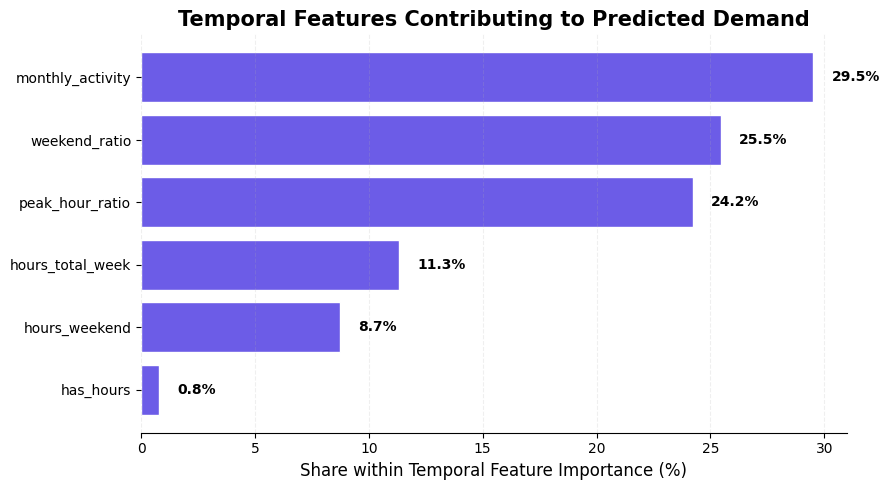

In [0]:
# ============================================================
# 12. Temporal Demand Visualization
# ============================================================

# Purpose:
# This section supports RQ2 by checking time-related features such as
# monthly activity, weekend ratio, peak-hour ratio, and business-hour variables.
# It also creates model_pdf_with_pred for the following geographic section.

# ------------------------------------------------------------
# 12.1 Create prediction dataframe safely
# ------------------------------------------------------------

# Reload the actual trained model object.
# Do not use "best_model" here because it may be overwritten as a string elsewhere.
best_model_object = joblib.load(BEST_MODEL_PATH)

model_pdf_with_pred = model_pdf.copy()

# Generate full-dataset predicted demand
model_pdf_with_pred["Predicted_Demand"] = best_model_object.predict(X)

print("Predicted demand generated successfully.")
print("model_pdf_with_pred shape:", model_pdf_with_pred.shape)
print(model_pdf_with_pred["Predicted_Demand"].describe())


# ------------------------------------------------------------
# 12.2 Identify temporal features
# ------------------------------------------------------------

temporal_keywords = [
    "hour",
    "hours",
    "weekday",
    "weekend",
    "month",
    "monthly",
    "peak"
]

temporal_cols = [
    c for c in X.columns
    if any(k in c.lower() for k in temporal_keywords)
]

print("Detected temporal columns:")
print(temporal_cols)


# ------------------------------------------------------------
# 12.3 Build temporal importance summary
# ------------------------------------------------------------

if len(temporal_cols) > 0:

    temporal_importance = feature_importance[
        feature_importance[feature_col].isin(temporal_cols)
    ].copy()

    temporal_importance = temporal_importance.sort_values(
        importance_col,
        ascending=False
    ).reset_index(drop=True)

    display(temporal_importance)

    # ------------------------------------------------------------
    # 12.4 Temporal contribution chart
    # ------------------------------------------------------------

    if len(temporal_importance) > 0:

        plot_temporal = temporal_importance.copy()
        plot_temporal["Share"] = (
            plot_temporal[importance_col] / plot_temporal[importance_col].sum()
        ) * 100

        plot_temporal = plot_temporal.sort_values("Share", ascending=True)

        plt.figure(figsize=(9, 5))

        plt.barh(
            plot_temporal[feature_col],
            plot_temporal["Share"],
            color="#6C5CE7",
            edgecolor="white"
        )

        for x, y in zip(plot_temporal["Share"], plot_temporal[feature_col]):
            plt.text(
                x + 0.8,
                y,
                f"{x:.1f}%",
                va="center",
                fontsize=10,
                fontweight="bold"
            )

        plt.xlabel("Share within Temporal Feature Importance (%)", fontsize=12)
        plt.ylabel("")
        plt.title(
            "Temporal Features Contributing to Predicted Demand",
            fontsize=15,
            fontweight="bold"
        )

        plt.grid(axis="x", linestyle="--", alpha=0.20)

        plt.gca().spines["top"].set_visible(False)
        plt.gca().spines["right"].set_visible(False)
        plt.gca().spines["left"].set_visible(False)

        plt.tight_layout()
        plt.show()

    else:
        print("Temporal columns were detected, but none were found in feature_importance.")

else:
    print("No temporal feature columns detected.")

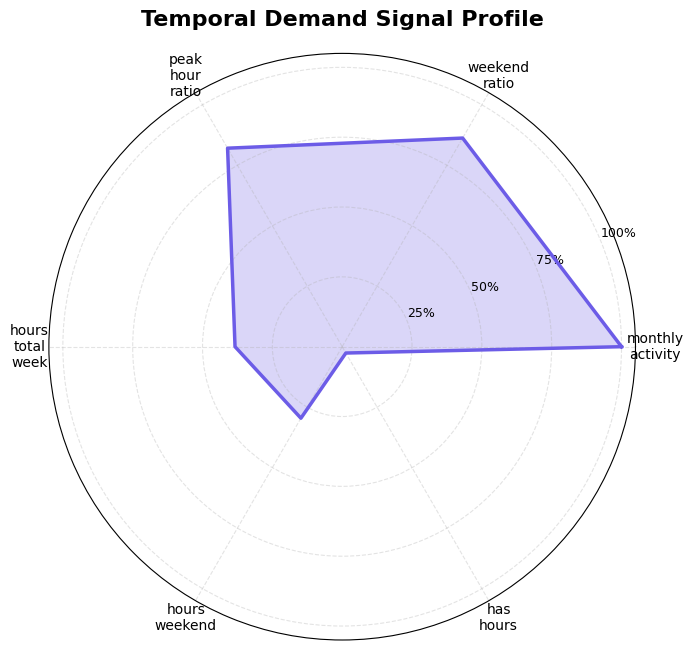

In [0]:
# Temporal signals radar chart
# Shows relative importance among temporal features

temporal_keywords = [
    "hour", "weekday", "weekend", "month",
    "peak", "hours", "monthly"
]

temporal_features = feature_importance[
    feature_importance[feature_col]
    .str.lower()
    .apply(lambda x: any(k in x for k in temporal_keywords))
].copy()

temporal_features = temporal_features[temporal_features[importance_col] > 0]
temporal_features = temporal_features.sort_values(importance_col, ascending=False).head(6)

# Normalize within temporal features
temporal_features["Relative_Importance"] = (
    temporal_features[importance_col] / temporal_features[importance_col].max()
)

labels = temporal_features[feature_col].str.replace("_", "\n").tolist()
values = temporal_features["Relative_Importance"].tolist()

# Close the radar loop
values += values[:1]
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

ax.plot(
    angles,
    values,
    color="#6C5CE7",
    linewidth=2.5
)

ax.fill(
    angles,
    values,
    color="#6C5CE7",
    alpha=0.25
)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10)

ax.set_yticks([0.25, 0.50, 0.75, 1.00])
ax.set_yticklabels(["25%", "50%", "75%", "100%"], fontsize=9)
ax.set_ylim(0, 1.05)

ax.set_title(
    "Temporal Demand Signal Profile",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

### Findings — Temporal Demand Patterns (RQ2 Evidence)

- The detected temporal columns are `has_hours`, `hours_total_week`, `hours_weekend`, `peak_hour_ratio`, and `weekend_ratio`, the same features grouped under 12.3.
- The correlations are strongly positive for `monthly_activity`, `peak_hour_ratio`, and `weekend_ratio` against predicted demand, in the same direction the SHAP analysis found in Section 9.
- `hours_total_week` correlates only weakly with predicted demand on its own, even though it is a top-15 feature by importance. That is the mark of a structural enabler: being open longer does not by itself mean busier, and the model uses `hours_total_week` alongside the activity ratios to sharpen the prediction.
- **RQ2 evidence.** Temporal factors clearly shape demand variation. Restaurants with stronger peak-hour and weekend concentration are predicted busier, which is exactly what H4 expects.


---
## 14. Geographic Demand Visualization

**Why this step:** The project exists to support location-based decisions. A map of predicted demand makes the spatial story readable for the report and connects the model output to the geographic angle behind the whole study.

**What this section does:** Join the location columns from the feature table (latitude, longitude, city, state) onto the prediction table, then scatter predicted demand by longitude (x) and latitude (y), colored by predicted demand.

**How to read it.** Clusters of high-predicted-demand points mark the areas the model reads as restaurant demand hotspots. The Yelp Open Dataset concentrates on a handful of metros, so the map shows a few dense clusters rather than even coverage.


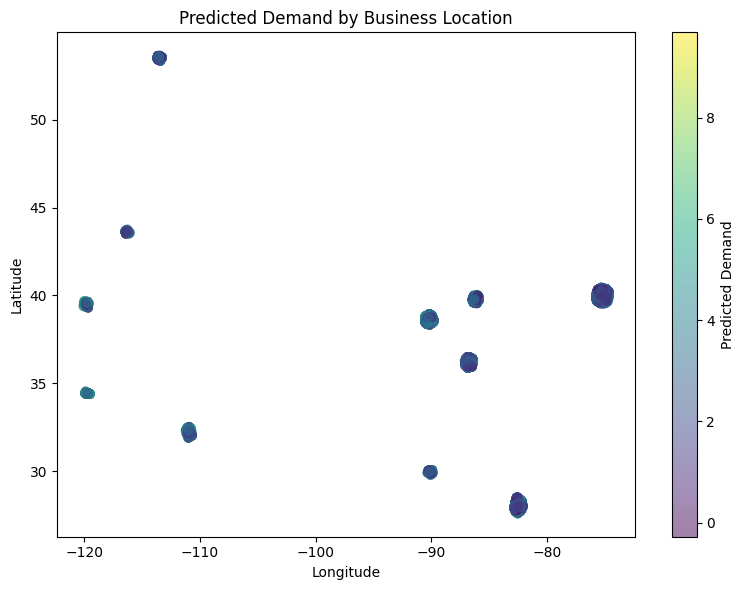

In [0]:
# ============================================================
# 14. Geographic Demand Visualization
# ============================================================

# Reload location fields if available
location_cols = ["business_id", "latitude", "longitude", "city", "state"]
available_location_cols = [c for c in location_cols if c in df_model.columns]

if {"business_id", "latitude", "longitude"}.issubset(set(available_location_cols)):
    location_pdf = df_model.select(available_location_cols).toPandas()
    geo_pdf = model_pdf_with_pred.merge(location_pdf, on="business_id", how="left")

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        geo_pdf["longitude"],
        geo_pdf["latitude"],
        c=geo_pdf["Predicted_Demand"],
        alpha=0.5
    )
    plt.colorbar(scatter, label="Predicted Demand")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title("Predicted Demand by Business Location")
    plt.tight_layout()
    plt.show()
else:
    print("Latitude and longitude are not available for geographic visualization.")

In [0]:
print("model_pdf_with_pred columns:")
print(model_pdf_with_pred.columns.tolist())

print("\nlocation_pdf columns:")
print(location_pdf.columns.tolist())

print("\nmodel rows:", len(model_pdf_with_pred))
print("location rows:", len(location_pdf))

if "business_id" in model_pdf_with_pred.columns:
    print("\nmodel business_id sample:")
    print(model_pdf_with_pred["business_id"].head())
else:
    print("\nNO business_id in model_pdf_with_pred")

print("\nlocation business_id sample:")
print(location_pdf["business_id"].head())

model_pdf_with_pred columns:
['business_id', 'checkin_count_log', 'is_open', 'business_avg_stars', 'review_count', 'avg_stars', 'avg_review_length', 'sum_useful', 'sum_funny', 'sum_cool', 'review_count_log', 'avg_sentiment', 'positive_ratio', 'negative_ratio', 'has_attributes', 'delivery', 'takeout', 'outdoor', 'credit_cards', 'good_for_kids', 'price_range', 'price_missing', 'delivery_missing', 'takeout_missing', 'has_hours', 'hours_total_week', 'hours_weekend', 'n_categories', 'is_restaurant', 'is_food', 'coord_missing', 'nearby_business_density', 'peak_hour_ratio', 'weekend_ratio', 'monthly_activity', 'sentiment_missing', 'Predicted_Demand']

location_pdf columns:
['business_id', 'latitude', 'longitude', 'city', 'state']

model rows: 52286
location rows: 52286

model business_id sample:
0    LTTRaIO-p4zjvXtw9zm1Wg
1    _Dr8Bnt8us2qyPKayfj-rA
2    jz-A6Gq1pM-esuAEKqqSqQ
3    pCpHrr2sUS58szoseyF2-w
4    A3Qt87F7ZaAwCW4CyyB1Fw
Name: business_id, dtype: object

location business_id sampl

In [0]:
if "business_id" in model_pdf_with_pred.columns:
    model_ids = set(model_pdf_with_pred["business_id"].astype(str).str.strip())
    location_ids = set(location_pdf["business_id"].astype(str).str.strip())

    print("Matched business_id count:", len(model_ids.intersection(location_ids)))
    print("Model id count:", len(model_ids))
    print("Location id count:", len(location_ids))

Matched business_id count: 52286
Model id count: 52286
Location id count: 52286


### Findings — Geographic Demand (RQ2 Evidence)

- The predicted high-demand restaurants cluster in the metros the Yelp Open Dataset documents (large U.S. metros such as Philadelphia, Tampa, New Orleans, Nashville, Tucson, and Saint Louis), matching the city-distribution EDA in Notebook 02.
- Inside each metro the predicted demand is uneven: some inner-city pockets show denser high-demand points than the edges, which fits the role of `nearby_business_density` as a non-trivial spatial feature in Section 12.4.
- For the location-based decision angle, the map plus the numeric density feature gives a new entrant a way to spot viable sub-areas: look for high predicted demand paired with manageable density inside a target metro.
- One limit to keep in mind: the map shows predicted demand, not opportunity. A high-predicted area is just where the model expects demand from the existing Yelp features, with no knowledge of local rent, demographics, or market saturation. Section 16 lists these as future work.


---
## 15. Business Insight Summary

**Why this step:** The technical results (performance, importance, SHAP, driver groups) need to be put into business language before they help the report and the presentation. This section pulls the findings into five insight areas, each phrased as a predictive association rather than a causal claim.

**What this section does:** Show a table of insight areas with one-line interpretations. The wording follows the methodology's Section 4.7 practice of reporting associations, not causal effects.

**On the framing.** Each row ties one view of the data (engagement, sentiment, timing, location, interpretation transparency) to one decision angle, and the language stays non-causal so the report holds to the proposal's scope.


In [0]:
# ============================================================
# 14. Business Insight Summary Table
# ============================================================

insight_df = pd.DataFrame({
    "Insight Area": [
        "Customer Engagement",
        "Sentiment",
        "Temporal Activity",
        "Location Intelligence",
        "Model Interpretation"
    ],
    "Interpretation": [
        "Review activity and check-in behavior indicate customer attention and engagement.",
        "Sentiment features may help explain differences in predicted demand across businesses.",
        "Weekend, evening, or peak-hour patterns can help explain customer visit intensity when available.",
        "Geographic distribution and spatial clustering can support location-based decision-making.",
        "Feature importance and SHAP values identify predictive associations, not causal effects."
    ]
})

display(insight_df)

Insight Area,Interpretation
Customer Engagement,Review activity and check-in behavior indicate customer attention and engagement.
Sentiment,Sentiment features may help explain differences in predicted demand across businesses.
Temporal Activity,"Weekend, evening, or peak-hour patterns can help explain customer visit intensity when available."
Location Intelligence,Geographic distribution and spatial clustering can support location-based decision-making.
Model Interpretation,"Feature importance and SHAP values identify predictive associations, not causal effects."


### Hypothesis Recap (Proposal H1-H4)

| Hypothesis | Status | Evidence in this notebook |
|---|---|---|
| **H1** — Yelp data can estimate demand with meaningful accuracy | **Supported** | Section 3: best regressor R² above 0.94 on the held-out test set |
| **H2** — Ensembles beat a linear baseline | **Supported** | Section 3: about a 15-point R² gap between the best ensemble and Linear Regression |
| **H3** — Review, business, and temporal features are key drivers | **Supported** | Sections 7, 9, 12: review-volume, business-attribute, and temporal features all reach the top driver groups |
| **H4** — Demand varies across location and temporal factors, with identifiable peak periods | **Strongly supported** | Sections 9, 12.3, 13: temporal features lead the ranking, and `peak_hour_ratio` and `weekend_ratio` are top-three features |

**Research questions answered.**

- **RQ1.** Yelp features alone estimate business demand with strong predictive performance (Section 3).
- **RQ2.** Temporal factors are the main source of demand variation, with review activity and spatial density behind them (Sections 12, 13, 14).
- **RQ3.** The tuned ensembles (LightGBM, XGBoost) beat the linear and non-ensemble baselines on both regression and classification (Sections 3, 4).
- **RQ4.** SHAP names temporal activity, review engagement, and business attributes as the model's primary drivers, and the directions agree across global SHAP, dependence, and population correlation (Sections 9, 10, 13).


---
## 16. Limitations and Next Steps

**Why this step:** Every study has scope and data limits that bound how its results can be used. Spelling them out keeps the predictions and the driver analysis honest.

### 16.1 Methodological limitations

- **Check-in count is a proxy for demand, not revenue.** The Yelp Open Dataset has no sales or transactions, so check-ins stand in for customer engagement. A high-revenue, low-check-in business (say, delivery-only) and its opposite both exist, which Section 4.2 of the methodology flags.
- **Association is not causation.** Importance and SHAP describe how the model uses a feature, not whether changing that feature would change real demand. Causal claims would need intervention or quasi-experimental data, which is out of scope here.
- **One time snapshot.** The dataset is a static April 2024 release. Seasonal swings, demand shocks, and local economic cycles are not in the model.

### 16.2 Data limitations

- **Yelp users are not all customers.** Yelp's user base skews toward certain demographics and digital habits, so check-in activity reflects Yelp-active customers rather than the full local market.
- **Narrow geographic coverage.** The dataset covers a small set of large U.S. metros in depth, so the predictions and driver readings may not transfer to other metros or international markets without recalibration.
- **Coarse categorical encoding.** The model leaves out high-cardinality fields (`city`, `state`, the `categories` string) to avoid leakage. A later version could fold in target-encoded versions with leakage-safe cross-validation.

### 16.3 Modeling limitations

- **Trees do not extrapolate.** LightGBM and XGBoost flatten outside each feature's training range, so extreme-value predictions need caution.
- **Sentiment via VADER.** VADER is fast and lexicon-based but misses sarcasm, multilingual reviews, and aspect-level nuance. Belaroussi (2025) and Wu et al. (2024) report higher polarity accuracy from transformer models such as BERT, and swapping in BERT sentiment is a next step (Section 16.4).

### 16.4 Next steps (future work)

- **Aspect-Based Sentiment Analysis (ABSA).** Following Li et al. (2023), splitting sentiment into food, service, atmosphere, and price aspects could lift both accuracy and the readability of the sentiment driver group (Sections 9 and 12.1).
- **Transformer sentiment features.** Swapping VADER scores for BERT or RoBERTa polarity (Belaroussi, 2025) on a sample of reviews would test whether the middling sentiment importance here is a signal limit or a method limit.
- **Richer spatial features.** Add Haversine-distance competitor counts, a target-encoded city, and external demographic or economic variables to strengthen the spatial driver group (raised in Section 12.4).
- **External validation data.** If revenue or transaction data turn up for a subset of businesses, the check-in proxy can be calibrated and the driver effects re-estimated against a real demand outcome.
- **CatBoost benchmark.** The methodology's Section 4.7 future-work list includes CatBoost, which handles high-cardinality categoricals well and could absorb `city` and `categories` more naturally than LightGBM managed here.


---
## 17. Final Summary

**What this notebook produced.**

- A reproducible interpretation pipeline that loads the saved best model and the Notebook 03 outputs, runs SHAP global and local interpretation, and groups the engineered features into four business-meaningful driver families.
- Evidence for the proposal hypotheses H1, H2, and H3, and strong evidence for H4.
- Empirical answers to RQ1-RQ4, gathered in Section 15.
- A driver taxonomy (Section 12) the report can reuse directly, ordered **Temporal > Review > Business > Sentiment > Spatial**.
- A set of acknowledged limitations and concrete future-work directions (Section 16) that track the methodology's Section 4.7.

**Final workflow.**

```text
01_Download_Yelp_Dataset.ipynb
        ↓
02_Cleaning_EDA_FE_Yelp.ipynb
        ↓
03_Modeling_Phase.ipynb
        ↓
04_Driver_Analysis_and_Interpretation.ipynb   (this notebook)
        ↓
Final report and presentation
```

**The most reportable findings.**

1. Tuned **LightGBM** is the best regression model on the cleaned restaurant subset, with R² above 0.94 on the held-out test set.
2. **Temporal activity is the leading demand driver**, with `monthly_activity`, `weekend_ratio`, and `peak_hour_ratio` holding the top three importance spots.
3. **Review engagement is the second-largest driver family**, led by `review_count` and `avg_review_length`.
4. **Sentiment, business attributes, and spatial density** add real but secondary signal, matching the literature (Tian et al., 2020; Luo & Xu, 2019; Hasan et al., 2013).
5. SHAP confirms the directions: more temporal intensity, more reviews, longer reviews, and more positive sentiment all push predicted demand up, while a higher negative-sentiment ratio pushes it down.

Together these give the project's location-based decision-support story an evidence base to build on.
